---------------------
## **IMPORTS AND LOAD IMAGE**
Details about the functions included in this subsection are outlined in the [`1.0_image_setup`](1.0_image_setup.ipynb) notebook. Please visit that notebook first if you are confused about any of the code included here.

#### &#x1F3C3; **Run code; no user input required**

In [1]:
from pathlib import Path
import os
import seaborn as sns

import numpy as np
import pandas as pd
import napari
from napari.utils.notebook_display import nbscreenshot

from skimage.morphology import binary_dilation, binary_erosion
from skimage.segmentation import clear_border
import numpy as np

from infer_subc.core.file_io import (read_czi_image, 
                                     export_inferred_organelle,
                                     list_image_files,
                                     sample_input)
from infer_subc.core.img import *
from infer_subc.organelles import non_linear_cellmask_transform

%load_ext autoreload
%autoreload 2

#### &#x1F6D1; &#x270D; **User Input Required:**

Please specify the following information about your data: `sample_data_type`, `data_root_path`, `in_data_path`, `im_type`, and `out_data_path`.

In [16]:
### USER INPUT REQUIRED ###
sample_data_type = None


# Edit locations indicated by "USER SPECIFIED".
### MCZ
# data_root_path = Path(r"J:\Cohen Lab\Maria Clara\2_Lab data\1_Multispectral data\2026\iAstrocytes Differentiation") # r"J:\Cohen Lab\Kajal\For Shannon\iAstroD28")
# in_data_path = data_root_path / "iPSCs_SOX9NFIA1_MSi_BR2_noD28/unmixing" # "Deconvolution"
# im_type = ".czi"
# out_data_path = data_root_path / "20261006_SR_test-seg"

### MG
data_root_path = Path(r"C:\Users\Shannon\Desktop\Cell-nuc-mask_test-data")
in_data_path = data_root_path / "example-images"
im_type = ".tiff"
out_data_path = data_root_path / "20261028_SR_test-wocl"

#### &#x1F3C3; **Run code; no user input required**

In [17]:
# If sample_data_type is set to "neuron_1", "astrocyte", "neuron_2" or "iPSC" then the sample data is used and the directories are set
if sample_data_type != None:
    data_root_path, im_type, in_data_path, out_data_path = sample_input(sample_data_type)

# Create the output directory to save the segmentation outputs in.
if not Path.exists(out_data_path):
    Path.mkdir(out_data_path)
    print(f"making {out_data_path}")

# Create a list of the file paths for each image in the input folder. Select test image path.
img_file_list = list_image_files(in_data_path,im_type)
# img_file_list = sorted(in_data_path.glob(f"*{im_type}"))
pd.set_option('display.max_colwidth', None)
pd.DataFrame({"Image Name":img_file_list})

making C:\Users\Shannon\Desktop\Cell-nuc-mask_test-data\20261028_SR_test-wocl


,Image Name
0,C:\Users\Shannon\Desktop\Cell-nuc-mask_test-data\example-images\02242026_ZS_iPSCs_SOX9NFIA1_BR02_N07_Unmixing_cmle.ome.tiff
1,C:\Users\Shannon\Desktop\Cell-nuc-mask_test-data\example-images\03172026_ZS_iPSCs_SOX9NFIA1_BR03_N03_Unmixing_cmle.ome.tiff
2,C:\Users\Shannon\Desktop\Cell-nuc-mask_test-data\example-images\04092026_ZS_iAtro_day21_SOX9NFIA1_BR05_N07_Unmixing_cmle.ome.tiff
3,C:\Users\Shannon\Desktop\Cell-nuc-mask_test-data\example-images\04092026_ZS_iAtro_day21_SOX9NFIA1_BR05_N11_Unmixing_cmle.ome.tiff
4,C:\Users\Shannon\Desktop\Cell-nuc-mask_test-data\example-images\04102026_iAstrocytesD21_BFP2EEA1_125ng_mTurLAMP1_30ng_OxVenSiT_mAppRab11_30ng_PM_lipoLtx4hr_img11_zstack_Unmixing_decon.ome.tiff
5,C:\Users\Shannon\Desktop\Cell-nuc-mask_test-data\example-images\11192025_iNeurons_day_14_BFP2EEA1_mTurLAMP1_OxVenSiT_mAppRab11_PM_img18_zstack_Unmixing_decon.ome.tiff
6,C:\Users\Shannon\Desktop\Cell-nuc-mask_test-data\example-images\20260520_wtc_CMs_day21_ALLwell6_img18_Unmixing_cmle.ome.tiff
7,C:\Users\Shannon\Desktop\Cell-nuc-mask_test-data\example-images\20260813_wtc_ipsc_p47_ALLwell2_img8_Unmixing_cmle.ome.tiff


#### &#x1F6D1; &#x270D; **User Input Required:**

Use the list above to specify which image you wish to analyze based on its index: `test_img_n`

In [18]:
#### USER INPUT REQUIRED ###
test_img_n = 6

#### &#x1F3C3; **Run code; no user input required**

Metadata information
File path: C:\Users\Shannon\Desktop\Cell-nuc-mask_test-data\example-images\20260520_wtc_CMs_day21_ALLwell6_img18_Unmixing_cmle.ome.tiff
Channel 0 name: 20260520_wtc_CMs_day21_ALLwell6_img18_Unmixing_cmle.ome :: Channel 0
Channel 1 name: 20260520_wtc_CMs_day21_ALLwell6_img18_Unmixing_cmle.ome :: Channel 1
Channel 2 name: 20260520_wtc_CMs_day21_ALLwell6_img18_Unmixing_cmle.ome :: Channel 2
Channel 3 name: 20260520_wtc_CMs_day21_ALLwell6_img18_Unmixing_cmle.ome :: Channel 3
Channel 4 name: 20260520_wtc_CMs_day21_ALLwell6_img18_Unmixing_cmle.ome :: Channel 4
Channel 5 name: 20260520_wtc_CMs_day21_ALLwell6_img18_Unmixing_cmle.ome :: Channel 5
Channel 6 name: 20260520_wtc_CMs_day21_ALLwell6_img18_Unmixing_cmle.ome :: Channel 6
Channel 7 name: 20260520_wtc_CMs_day21_ALLwell6_img18_Unmixing_cmle.ome :: Channel 7
Channel 8 name: 20260520_wtc_CMs_day21_ALLwell6_img18_Unmixing_cmle.ome :: Channel 8
Channel 9 name: 20260520_wtc_CMs_day21_ALLwell6_img18_Unmixing_cmle.ome :: Cha

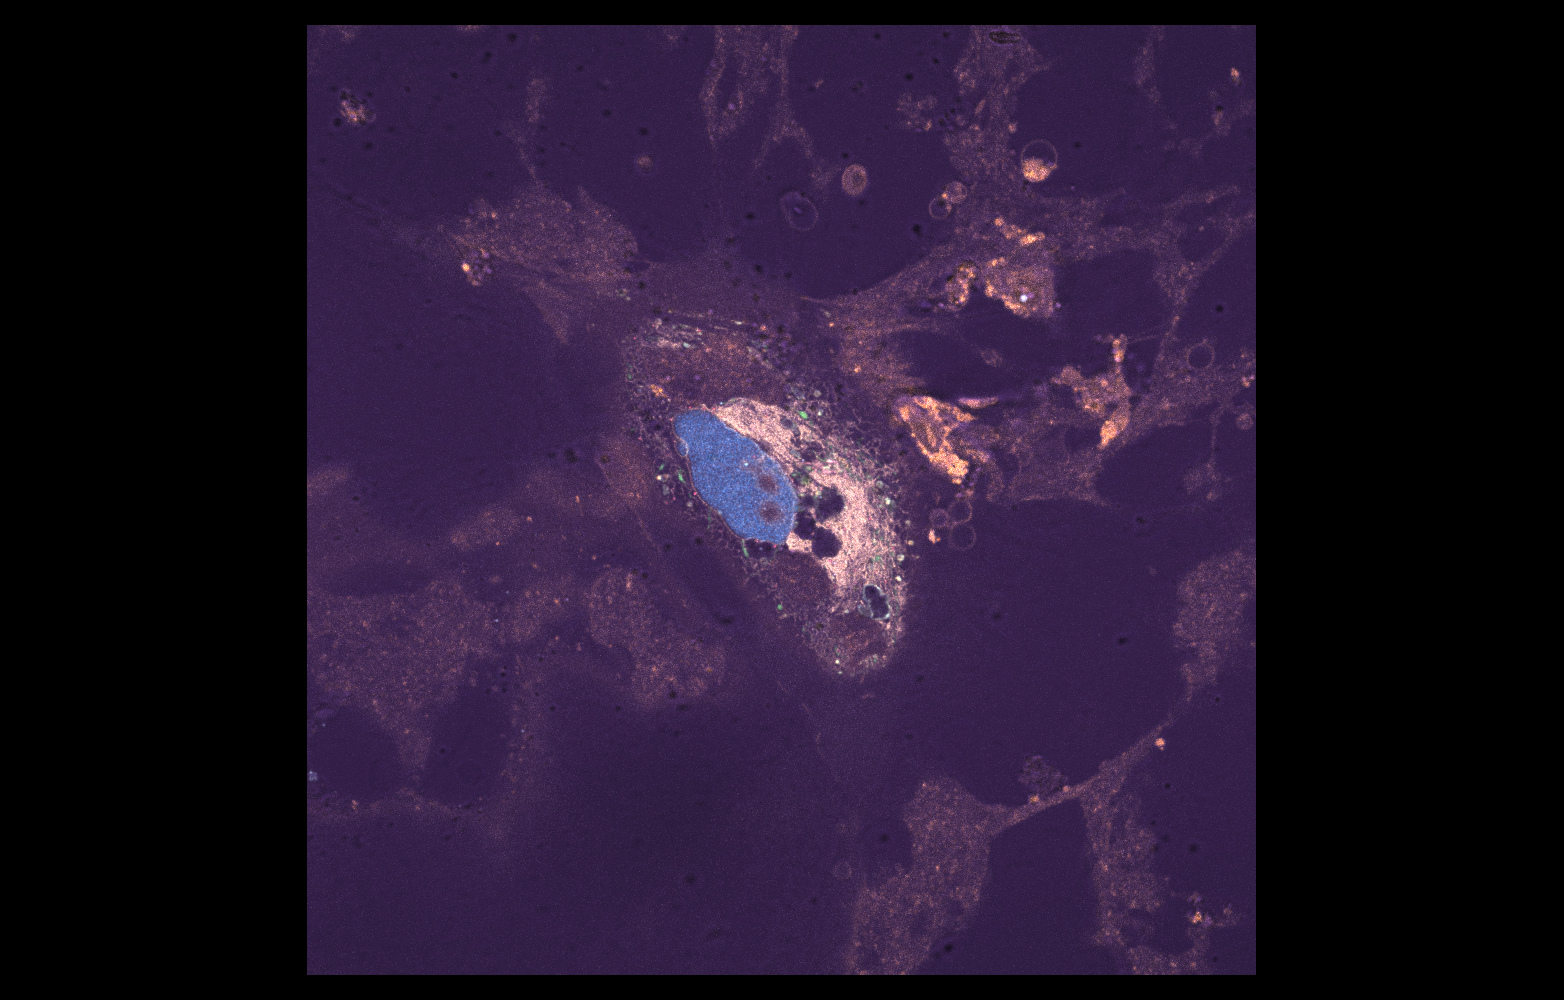

In [19]:
# Read in the image and metadata as an ndarray and dictionary from the test image selected above. 
test_img_name = img_file_list[test_img_n]
img_data,meta_dict = read_czi_image(test_img_name)

# Define some of the metadata features and print them.
channel_names = meta_dict['name']
meta = meta_dict['metadata']['aicsimage']
scale = meta_dict['scale']
channel_axis = meta_dict['channel_axis']
file_path = meta_dict['file_name']

print("Metadata information")
print(f"File path: {file_path}")
for i in list(range(len(channel_names))):
    print(f"Channel {i} name: {channel_names[i]}")
print(f"Scale (ZYX): {scale}")
print(f"Channel axis: {channel_axis}")

# open viewer and add images
viewer = napari.Viewer()
color_map = sns.color_palette("Paired").as_hex()
viewer.layers.clear()
for i in list(range(len(channel_names))):
    viewer.add_image(img_data[i],
                     scale=scale,
                     name=f"Channel {i}",
                     blending="additive",
                     colormap=color_map[i])
viewer.grid.enabled = False
viewer.reset_view()
print("\nProceed to Napari window to view your selected image.")

# screenshot viewer
nbscreenshot(viewer, canvas_only = True)

-----
## **Test implementation of waveorder & cytoland**

**Workflow:** channel 9 of `img_data` (a through-focus transmitted-light z-stack) &rarr; **waveorder** 3D quantitative phase imaging (QPI) reconstruction &rarr; **Cytoland VSCyto3D** virtual staining of nuclei + plasma membrane &rarr; 3D segmentation.

> **Environment note:** `waveorder` (v3) and `cytoland` require Python &ge; 3.12 and PyTorch, which the `infer-subc` environment (Python 3.10) cannot host. The heavy steps therefore run through [`waveorder_cytoland_worker.py`](waveorder_cytoland_worker.py) in a separate conda environment, and this notebook exchanges TIFF files with it. One-time setup (already done on this machine as `waveorder-cytoland`):
> ```
> conda create -n waveorder-cytoland python=3.12
> conda activate waveorder-cytoland
> pip install torch torchvision --index-url https://download.pytorch.org/whl/cu128   # or CPU build
> pip install waveorder cytoland tifffile scikit-image scipy
> pip install --force-reinstall --no-deps torch torchvision --index-url https://download.pytorch.org/whl/cu128   # only if pip replaced the CUDA build with a CPU one
> ```

#### &#x1F6D1; &#x270D; **User Input Required:**

Set the channel, optical parameters of the transmitted-light channel, and the paths. The voxel size is taken from the image metadata (`scale`, ZYX, assumed micrometers). Check `na_detection`, `na_illumination` and `wavelength_um` against your acquisition. If the phase looks contrast-inverted (nuclei dark instead of bright relative to background), toggle `invert_phase_contrast`.

In [20]:
### USER INPUT REQUIRED ###
bf_channel = 9                      # channel index in img_data to reconstruct

# Optics of the transmitted-light channel
wavelength_um = 0.532               # illumination wavelength (micrometers)
na_detection = 1.4                  # objective NA
na_illumination = 0.55               # condenser NA (must be <= ri_media)
ri_media = 1.5                      # refractive index of the imaging medium
z_padding = 1                       # z slices padded for axial boundary effects
invert_phase_contrast = False
regularization_strength = 0.1       # 1e-3 = Tikhonov regularization for waveorder; adjust this fine tune the outcome

# Cytoland / compute settings
worker_python = Path(r"C:\Users\Shannon\anaconda3\envs\waveorder-cytoland\python.exe")
checkpoint_path = Path.home() / ".cache" / "cytoland" / "VSCyto3D.ckpt"   # downloaded automatically if missing
device = "auto"                     # "auto", "cuda" or "cpu"
model_voxel_zyx_um = (0.27, 0.1, 0.1)  # voxel size VSCyto3D was trained on; the phase is resampled to this
tile_yx = 0                         # 0 = whole XY plane (recommended, no seams); falls back to blended tiles on GPU out-of-memory
halo_yx = 32                        # XY overlap used only when tiling
z_stride = 1                        # model-author maximum-overlap mode; slower, but reduces window seams

#### &#x1F3C3; **Run code; no user input required**

Writes channel `bf_channel` to a temporary TIFF, then runs waveorder + VSCyto3D in the worker environment (this can take several minutes for large volumes).

Channel 9 (20260520_wtc_CMs_day21_ALLwell6_img18_Unmixing_cmle.ome :: Channel 9): shape ZYX = (23, 1912, 1912), scale ZYX = (0.389118, 0.07064, 0.07064)
input (23, 1912, 1912)
waveorder phase reconstruction (native voxel size)...
resampled phase (23, 1912, 1912) -> (33, 1351, 1351) for the model ([0.389118, 0.07064, 0.07064] -> [0.27, 0.1, 0.1] um)
Cytoland VSCyto3D virtual staining...
done


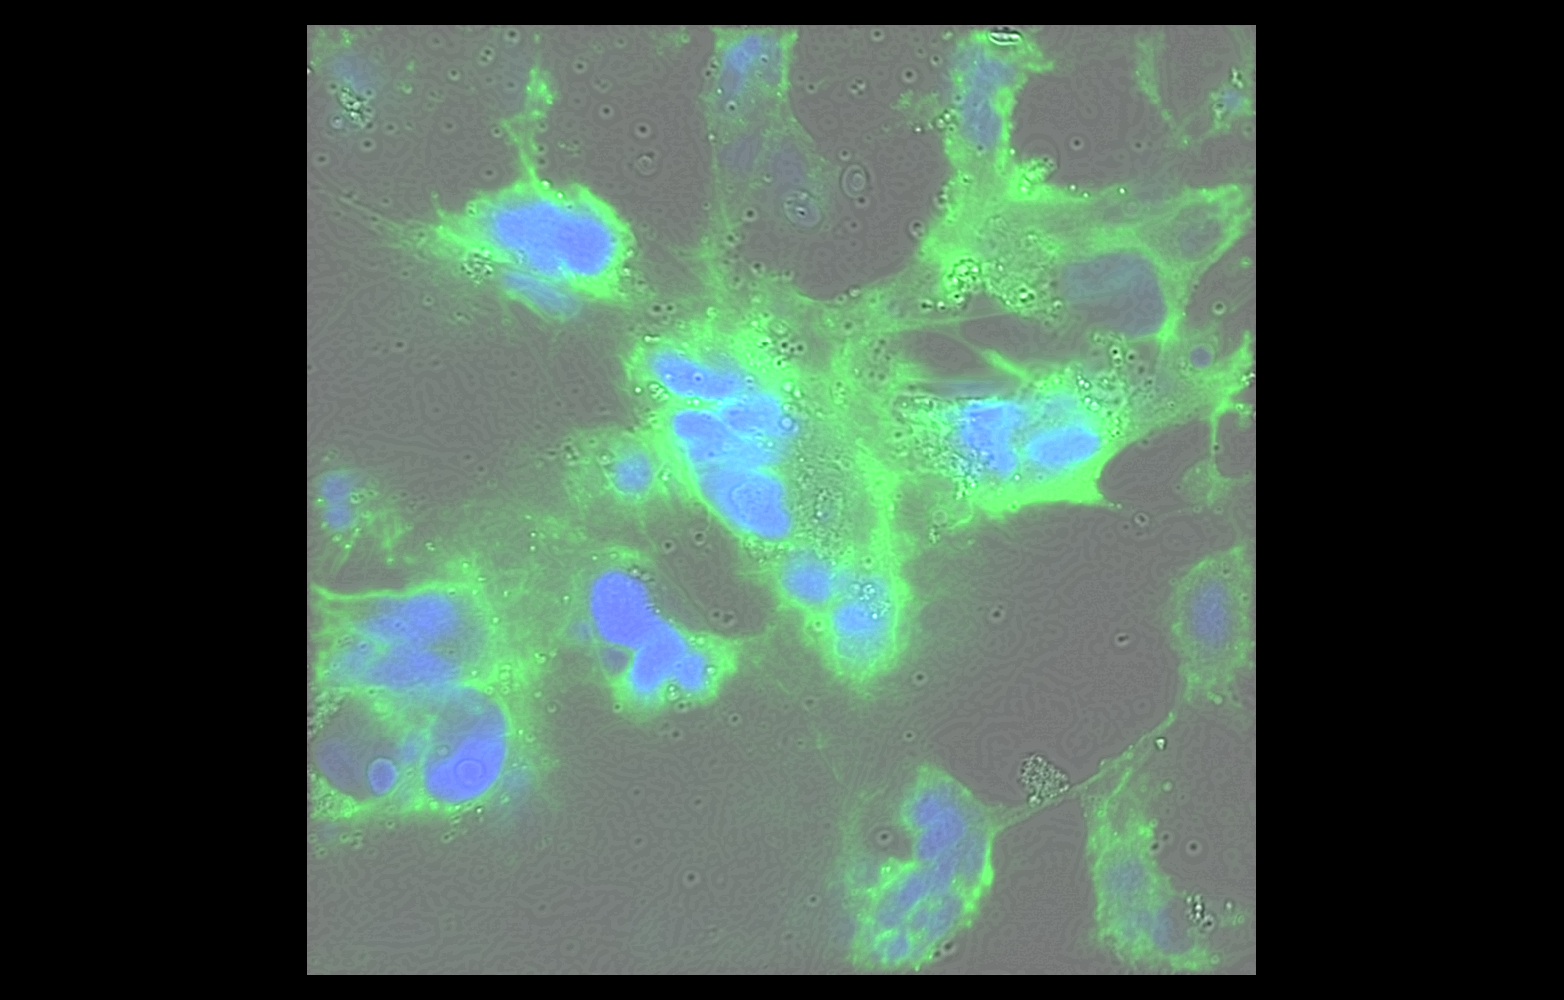

: 

In [ ]:
import json, subprocess, urllib.request
import tifffile

CKPT_URL = "https://public.czbiohub.org/comp.micro/viscy/VS_models/VSCyto3D/epoch=83-step=14532-loss=0.492.ckpt"
worker_script = Path("waveorder_cytoland_worker.py").resolve()
vs_dir = out_data_path / f"{test_img_name.stem}_waveorder_cytoland"
vs_dir.mkdir(parents=True, exist_ok=True)

# Download the VSCyto3D checkpoint once (~420 MB)
if not checkpoint_path.exists():
    checkpoint_path.parent.mkdir(parents=True, exist_ok=True)
    print(f"Downloading VSCyto3D checkpoint to {checkpoint_path} ...")
    urllib.request.urlretrieve(CKPT_URL, checkpoint_path)

# extract the brightfield channel and save it as a TIFF for the worker to read
bf_zyx = np.asarray(img_data[bf_channel], dtype=np.float32)
print(f"Channel {bf_channel} ({channel_names[bf_channel]}): shape ZYX = {bf_zyx.shape}, scale ZYX = {scale}")
tifffile.imwrite(vs_dir / "input_bf.tiff", bf_zyx)

# create a JSON file with the parameters for the worker script
params = dict(
    input_tiff=str(vs_dir / "input_bf.tiff"),
    output_dir=str(vs_dir),
    scale_zyx_um=[float(s) for s in scale],
    wavelength_um=wavelength_um,
    na_detection=na_detection,
    na_illumination=na_illumination,
    ri_media=ri_media,
    z_padding=z_padding,
    invert_phase_contrast=invert_phase_contrast,
    regularization_strength=regularization_strength,
    device=device,
    checkpoint=str(checkpoint_path),
    model_voxel_zyx_um=list(model_voxel_zyx_um),
    tile_yx=tile_yx,
    halo_yx=halo_yx,
    z_stride=z_stride,
)
params_file = vs_dir / "params.json"
params_file.write_text(json.dumps(params, indent=2))

# run the worker script in a subprocess and print its output
proc = subprocess.Popen([str(worker_python), str(worker_script), str(params_file)],
                        stdout=subprocess.PIPE, stderr=subprocess.STDOUT, text=True)
for line in proc.stdout:
    if "triton" not in line:
        print(line.rstrip())
if proc.wait() != 0:
    raise RuntimeError("waveorder/cytoland worker failed; see the log above.")

phase_zyx = tifffile.imread(vs_dir / "phase.tiff")
vs_nucleus = tifffile.imread(vs_dir / "vs_nucleus.tiff")
vs_membrane = tifffile.imread(vs_dir / "vs_membrane.tiff")

# viewer.layers.clear()
viewer.add_image(bf_zyx, scale=scale, name=f"Channel {bf_channel} (input)", colormap="gray")
viewer.add_image(((phase_zyx+1)*100).astype(int), scale=scale, name="waveorder phase", colormap="gray")
viewer.add_image(vs_nucleus, scale=scale, name="VS nucleus", colormap="blue", blending="additive")
viewer.add_image(vs_membrane, scale=scale, name="VS membrane", colormap="green", blending="additive")
viewer.reset_view()
nbscreenshot(viewer, canvas_only=True)

## **Segment nucleus and plasma membrane from the virtual stains**
#### &#x1F6D1; &#x270D; **User Input Required:**

Tune after inspecting the virtual-stain layers in napari. Thresholds are multipliers on the Otsu threshold of each smoothed virtual-stain channel.

In [ ]:
### USER INPUT REQUIRED ###
gauss_sigma = 1.0                   # smoothing (pixels) before thresholding
nuc_thresh_factor = 1.0             # >1 stricter, <1 more permissive
mem_thresh_factor = 1.0
nuc_min_size_um3 = 100.0            # remove nuclei smaller than this (cubic micrometers)
nuc_split_min_distance = 8          # min distance (pixels) between nuclear centers when splitting touching nuclei
cell_foreground_factor = 0.5        # fraction of the membrane Otsu threshold defining the cell/background boundary

#### &#x1F3C3; **Run code; no user input required**

Nuclei: threshold + distance-transform watershed to split touching nuclei. Plasma membrane: thresholded membrane signal; whole-cell regions are obtained by a watershed seeded from the nuclei that stops at the membrane signal.

In [ ]:
from scipy import ndimage as ndi
from skimage.filters import gaussian, threshold_otsu
from skimage.morphology import remove_small_objects, remove_small_holes
from skimage.segmentation import watershed, find_boundaries
from skimage.feature import peak_local_max

voxel_um3 = float(np.prod(scale))
nuc_s = gaussian(vs_nucleus, gauss_sigma, preserve_range=True)
mem_s = gaussian(vs_membrane, gauss_sigma, preserve_range=True)

# --- nucleus ---
nuc_thr = threshold_otsu(nuc_s) * nuc_thresh_factor
nuc_mask = nuc_s > nuc_thr
nuc_mask = remove_small_objects(nuc_mask, int(nuc_min_size_um3 / voxel_um3))
nuc_mask = remove_small_holes(nuc_mask, int(nuc_min_size_um3 / voxel_um3))

dist = ndi.distance_transform_edt(nuc_mask, sampling=scale)
peaks = peak_local_max(ndi.gaussian_filter(dist, 1), min_distance=nuc_split_min_distance,
                       labels=ndi.label(nuc_mask)[0], exclude_border=False)
markers = np.zeros(nuc_mask.shape, dtype=np.int32)
if len(peaks):
    markers[tuple(peaks.T)] = np.arange(1, len(peaks) + 1)
nuc_labels = watershed(-dist, markers, mask=nuc_mask).astype(np.int32)

# --- plasma membrane ---
mem_thr = threshold_otsu(mem_s) * mem_thresh_factor
membrane_mask = mem_s > mem_thr

# --- whole cells: watershed from nuclei on the membrane signal ---
cell_fg = mem_s > threshold_otsu(mem_s) * cell_foreground_factor
cell_fg |= nuc_mask
cell_labels = watershed(mem_s, markers=nuc_labels, mask=cell_fg).astype(np.int32)
membrane_labels = np.where(find_boundaries(cell_labels, mode="inner") & membrane_mask, cell_labels, 0).astype(np.int32)

print(f"Nuclei: {nuc_labels.max()} | cells: {len(np.unique(cell_labels)) - 1} | "
      f"membrane voxels: {int(membrane_mask.sum())}")

for name, lbl in [("nucleus", nuc_labels), ("cell", cell_labels), ("membrane_mask", membrane_mask.astype(np.uint8)),
                  ("membrane_labels", membrane_labels)]:
    if name in [l.name for l in viewer.layers]:
        viewer.layers.remove(name)
    viewer.add_labels(lbl, scale=scale, name=name, opacity=0.5)
nbscreenshot(viewer, canvas_only=True)

#### &#x1F3C3; **Run code to save the segmentations**

In [ ]:
stem = test_img_name.stem
for name, arr in [("nuc", nuc_labels), ("cell", cell_labels), ("PM_mask", membrane_mask.astype(np.uint8)),
                  ("PM_labels", membrane_labels)]:
    tifffile.imwrite(out_data_path / f"{stem}-ch{bf_channel}_{name}.tiff", arr.astype(np.uint16 if arr.max() > 255 else np.uint8))
print(f"Saved segmentations to {out_data_path}")